### Settings of the Wasserstein distance

<div class="alert alert-block alert-info">
<b>PILOT</b>

In this tutorial we show the settings of `pl.tl.wasserstein_distance` and their effect on the trajectory, the UMAP of the samples and the computation time, using the Myocardial Infarction data. You can download the Anndata (h5ad) file from [here](https://costalab.ukaachen.de/open_data/PILOT/myocardial_infarction.h5ad), and place it in the _Datasets_ folder.

PILOT describes every sample by its cell type proportions. The Wasserstein distance between two samples is the cheapest way to turn the proportions of one sample into those of the other. Two choices define it:

1. <b>The cost matrix</b>: how expensive it is to move cells from one cell type to another, i.e. how different two cell types are (`cost_method`, `metric`, `n_pcs`, `centroid`).
2. <b>The transport method</b>: how the cells are moved between two samples (`regularized`).

The default settings are the ones of the PILOT paper and work well for this data. The other settings are useful for other data sets, e.g. with many cell types, rare cell types or strong batch effects.
</div>

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import pilotpy as pl
from sklearn.metrics import silhouette_score

##### Reading Anndata

In [ ]:
adata = sc.read_h5ad('Datasets/myocardial_infarction.h5ad')

##### A small helper to compare the settings:
<div class="alert alert-block alert-info">
For each setting, the helper below computes the Wasserstein distance, measures the time, and shows the trajectory and the UMAP of the samples colored by status side by side.

It also computes the Silhouette score of the status on the distances: 1 means that control and IZ samples are perfectly separated, 0 that they are mixed. It is a rough check only. A setting should not be chosen only because it separates the known groups best; the goal of PILOT is to find the disease progression, also within the groups.
</div>

In [ ]:
results = []

def run_setting(name, **settings):
    start = time.perf_counter()
    pl.tl.wasserstein_distance(
        adata,
        emb_matrix = 'PCA',
        clusters_col = 'cell_subtype',
        sample_col = 'sampleID',
        status = 'Status',
        **settings)
    seconds = time.perf_counter() - start
    distances = (adata.uns['EMD'] + adata.uns['EMD'].T) / 2
    np.fill_diagonal(distances, 0)
    silhouette = silhouette_score(distances, adata.uns['real_labels'], metric = 'precomputed')
    results.append({'setting': name, 'seconds': round(seconds, 1), 'silhouette': round(silhouette, 3)})

    fig, axes = plt.subplots(1, 2, figsize = (13, 5))
    pl.pl.trajectory(adata, ax = axes[0], plot_titel = f'Trajectory: {name}')
    pl.pl.umap_samples(adata, ax = axes[1], title = f'UMAP: {name}')
    plt.tight_layout()
    plt.show()

##### Default settings:
<div class="alert alert-block alert-info">
The default cost is the distance between the centers (median) of the cell types in the PCA space, with the cosine metric, and exact optimal transport.
</div>

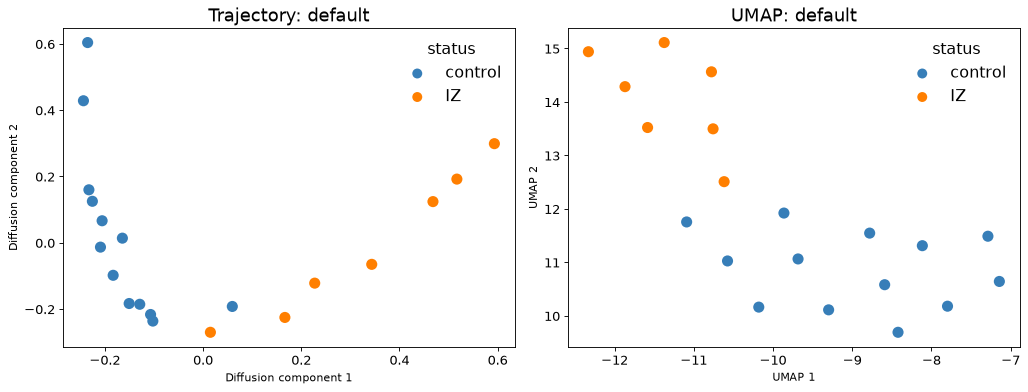

In [ ]:
run_setting('default')

##### Number of principal components (`n_pcs`):
<div class="alert alert-block alert-info">
`n_pcs` uses only the first principal components to compute the cost. Few components keep only the main differences between the cell types; more components also keep the finer ones. By default all components of `emb_matrix` are used (30 in this data).
</div>

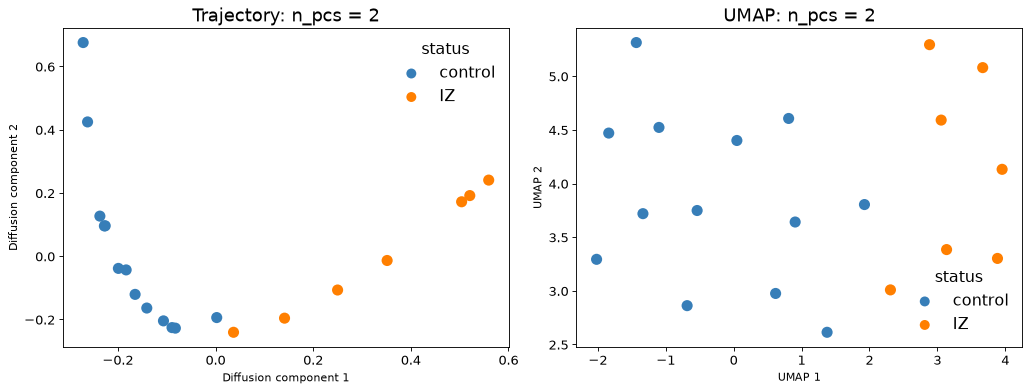

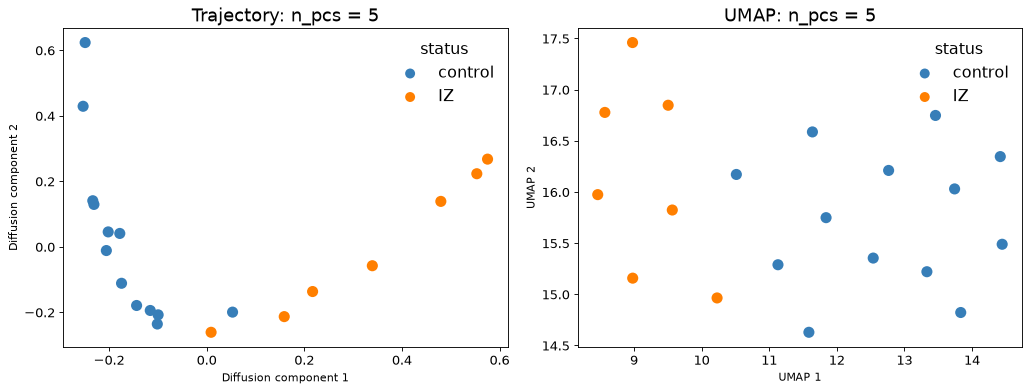

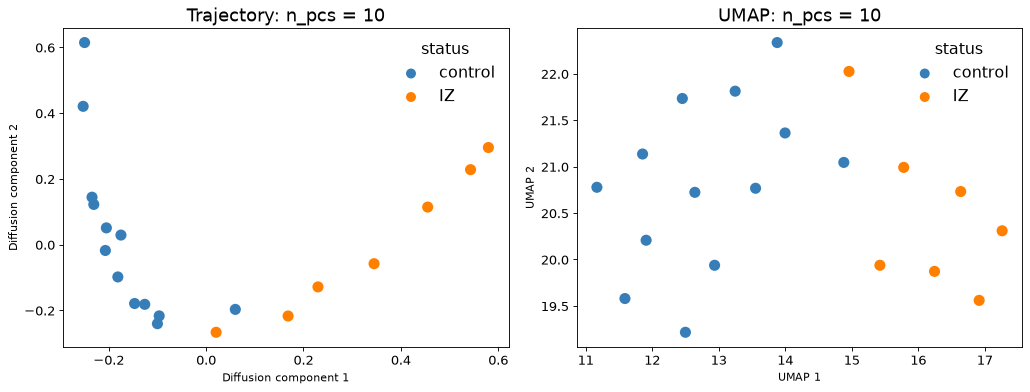

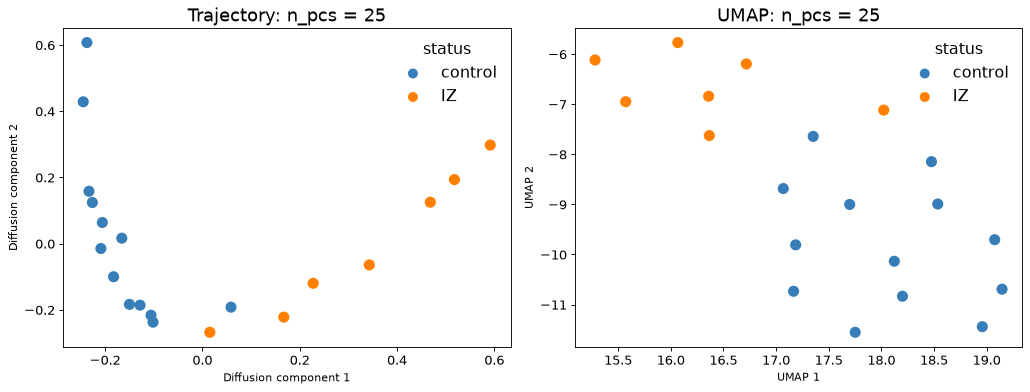

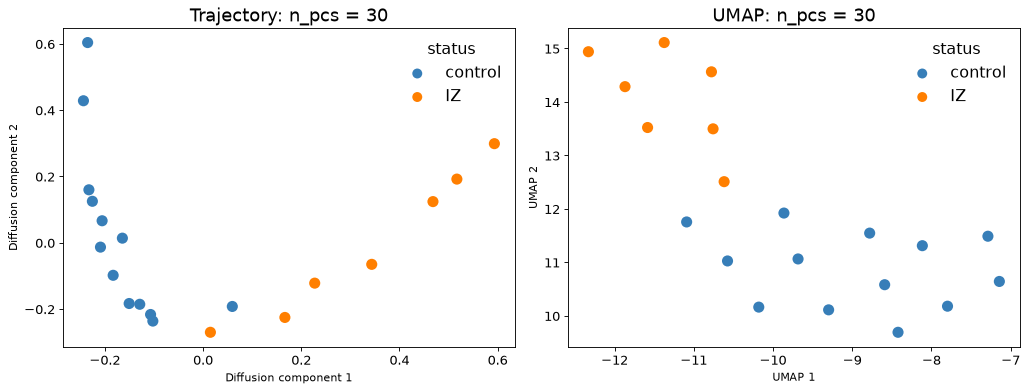

In [ ]:
for n_pcs in [2, 5, 10, 25, 30]:
    run_setting(f'n_pcs = {n_pcs}', n_pcs = n_pcs)

##### Center of a cell type (`centroid`):
<div class="alert alert-block alert-info">
With the default `cost_method = 'centroid'`, each cell type is represented by one point: the `'median'` (default, robust to outlier cells) or the `'mean'` of its cells.
</div>

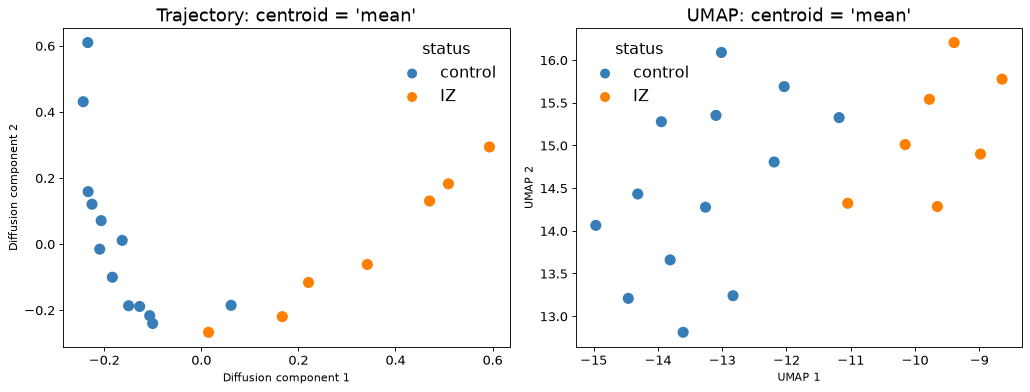

In [ ]:
run_setting("centroid = 'mean'", centroid = 'mean')

##### Metric (`metric`):
<div class="alert alert-block alert-info">
The metric measures the distance between two cell types. All possible values:

- `'cosine'` (default): angle between the profiles, ignores their size.
- `'correlation'`: 1 - Pearson correlation (cosine after centering).
- `'euclidean'`: straight-line distance; also compares the size.
- `'sqeuclidean'`: squared euclidean; far cell types cost much more.
- `'cityblock'` (Manhattan): sum of the absolute differences.
- `'chebyshev'`: largest difference in one dimension.
- `'minkowski'`: generalisation of euclidean and cityblock.
- `'canberra'`: sum of relative differences; sensitive to small values.
- `'braycurtis'`: relative sum of differences; meant for non-negative values.
- `'seuclidean'`: euclidean with every dimension scaled by its variance.
- `'mahalanobis'`: euclidean that takes correlated dimensions into account.
- `'jensenshannon'`: for non-negative values that are like proportions, e.g. pathomics features or `cost_method = 'expression'`; not for PCA, so it is not shown here.
</div>

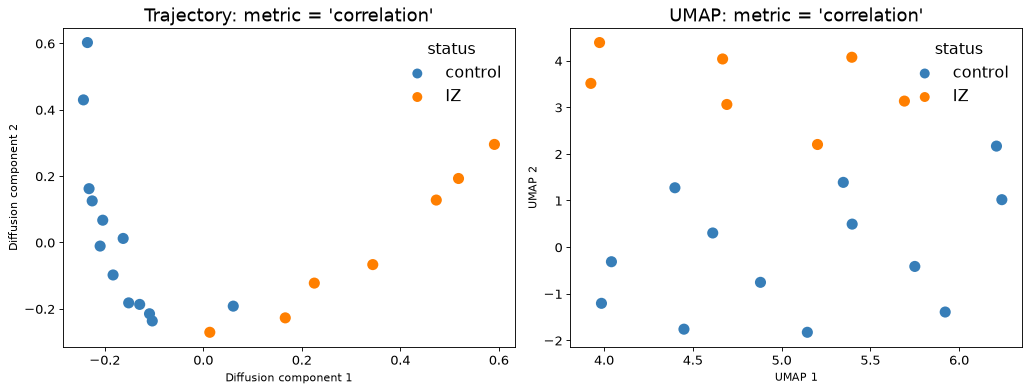

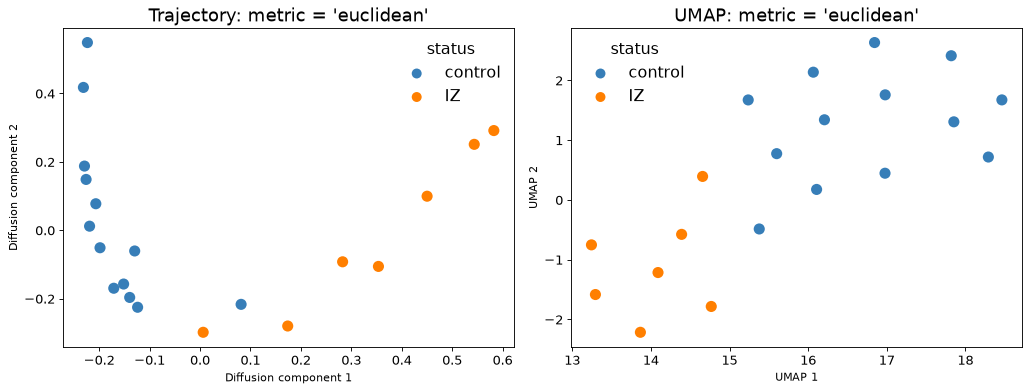

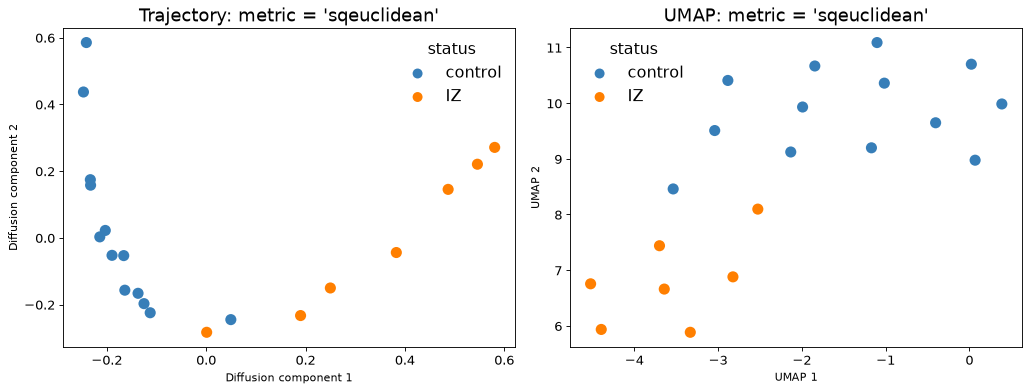

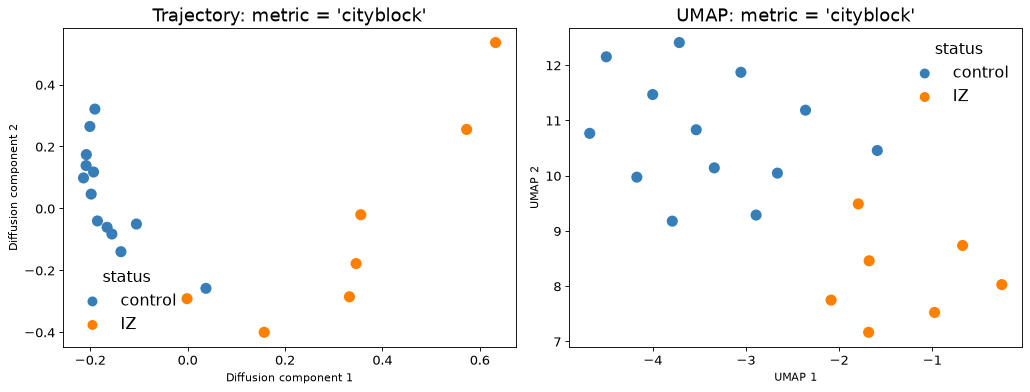

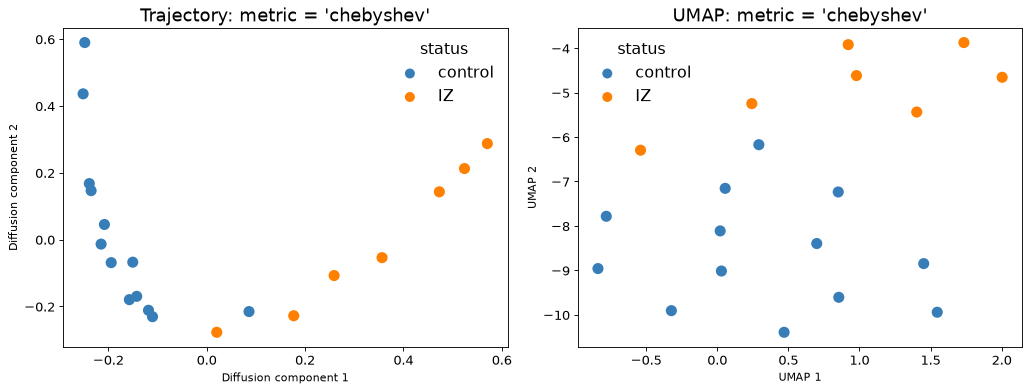

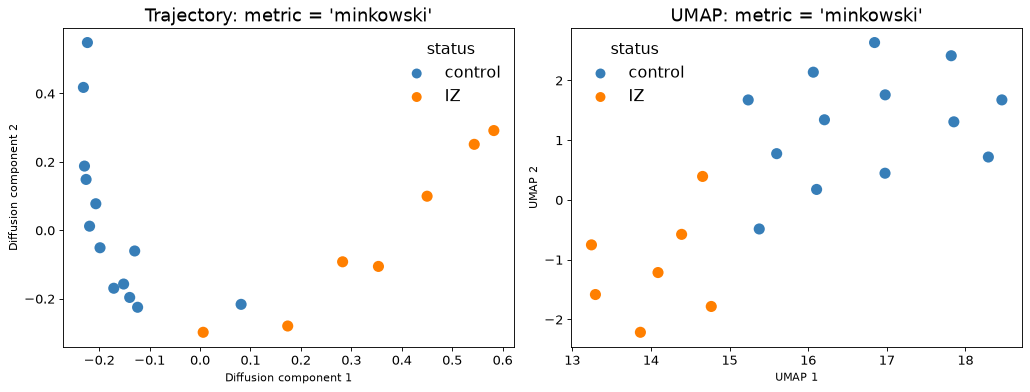

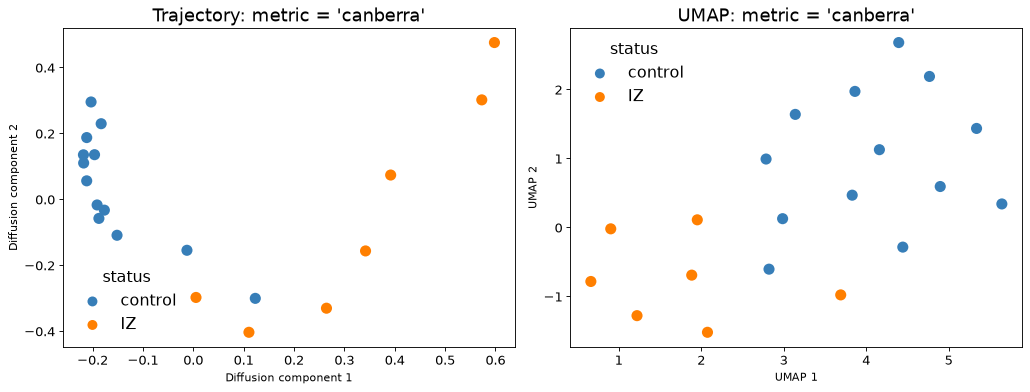

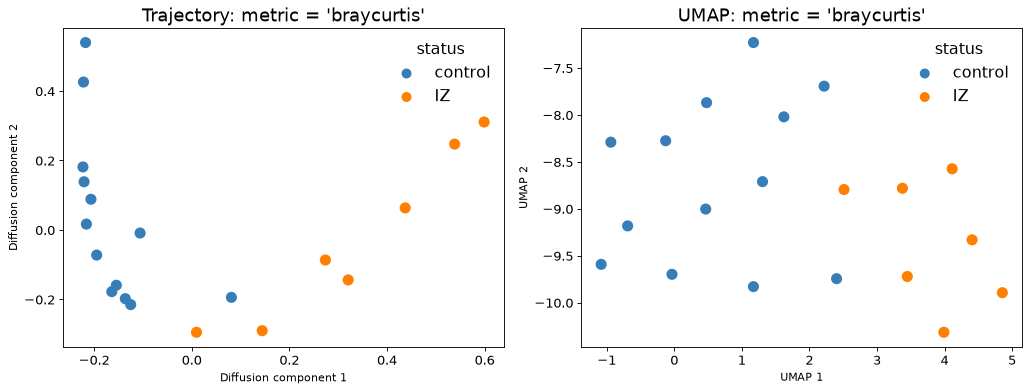

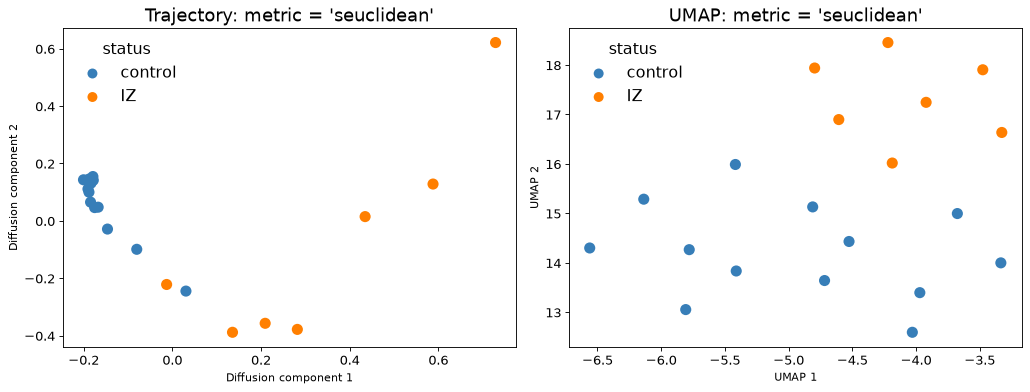

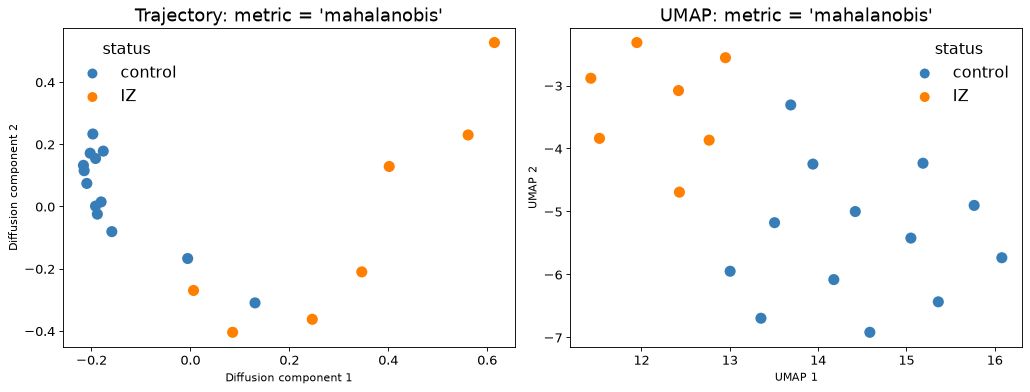

In [ ]:
for metric in ['correlation', 'euclidean', 'sqeuclidean', 'cityblock', 'chebyshev', 'minkowski',
               'canberra', 'braycurtis', 'seuclidean', 'mahalanobis']:
    run_setting(f"metric = '{metric}'", metric = metric)

##### Other ways to compute the cost (`cost_method`):
<div class="alert alert-block alert-info">
Besides the distance between the centers of the cell types (`'centroid'`, default), PILOT can compute the cost in other ways. All of them give a small cost for similar cell types and a large cost for different ones, so they can be used for the Wasserstein distance:

- `'distribution'`: compares all cells of two cell types, not only their centers (energy distance), so the spread and the sub-groups of a cell type count too. `max_cells` (default 500) random cells per cell type are used.
- `'graph'`: two cell types are close when many of their cells are neighbors in the k-nearest-neighbor graph of the cells (like PAGA), also through intermediate cell types (e.g. healthy, then damaged cardiomyocytes). `n_neighbors_cost` (default 15) sets the number of neighbors.
- `'expression'`: distance between the average gene expression (pseudobulk) of the cell types on the `n_genes` (default 2000) most variable genes. It needs counts in `adata.X` (or in `layer`).
- `'jaccard'`: Jaccard distance between the marker genes of the cell types: 1 - (shared markers / all markers). `n_markers` (default 100) markers per cell type are used. It needs counts in `adata.X` (or in `layer`).
- `'precomputed'`: your own cost matrix, given with `cost`.
</div>

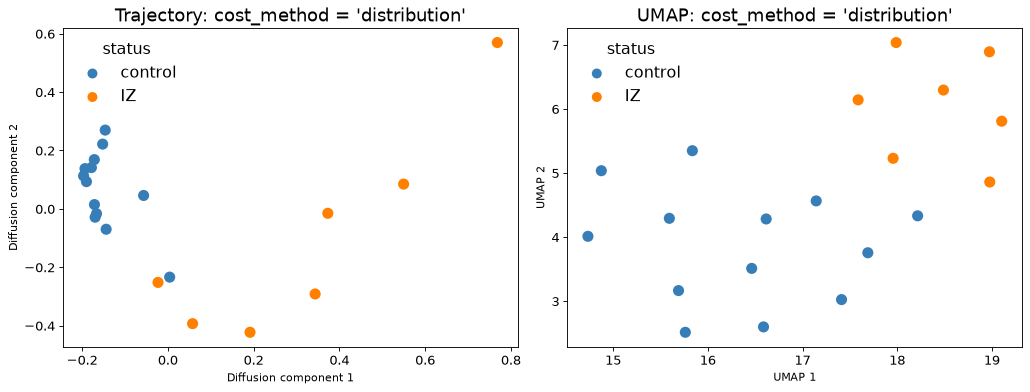

In [ ]:
run_setting("cost_method = 'distribution'", cost_method = 'distribution', metric = 'euclidean')

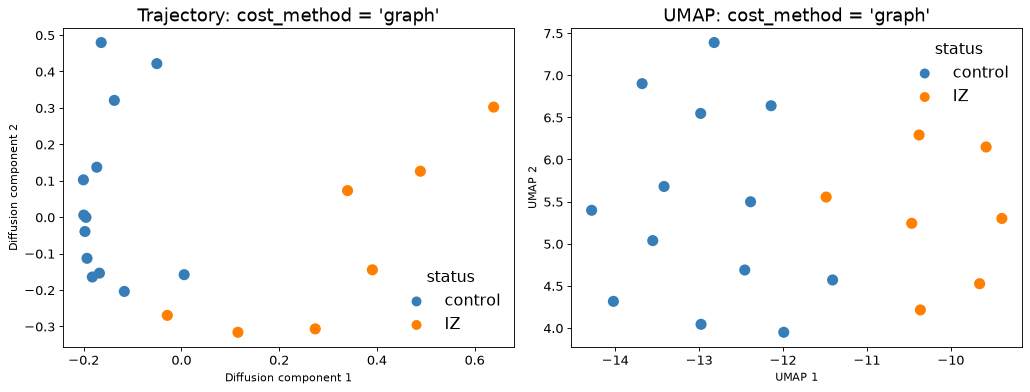

In [ ]:
run_setting("cost_method = 'graph'", cost_method = 'graph')

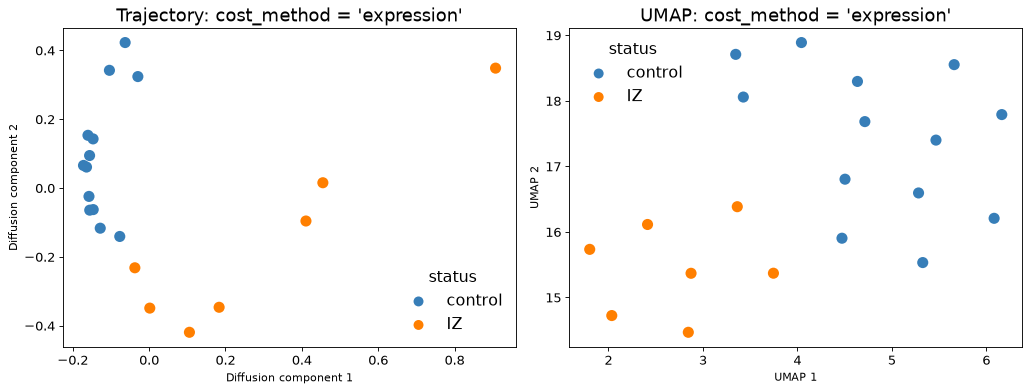

In [ ]:
run_setting("cost_method = 'expression'", cost_method = 'expression', metric = 'correlation')

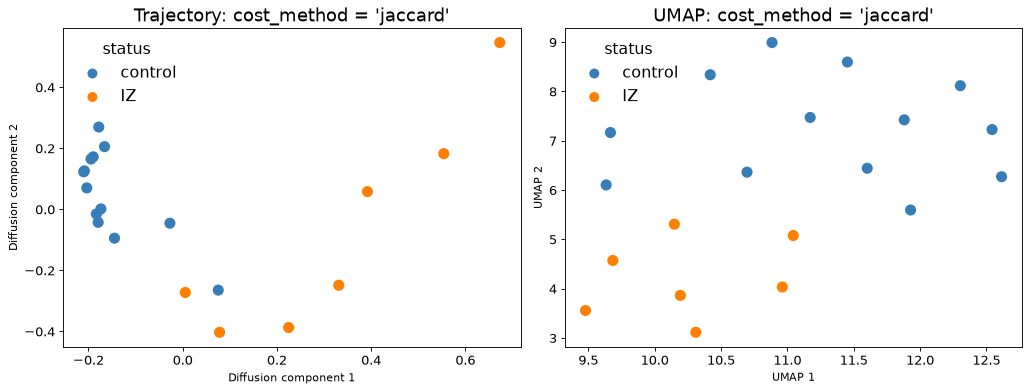

In [ ]:
run_setting("cost_method = 'jaccard'", cost_method = 'jaccard')

As an example of your own cost matrix, we use the cell type hierarchy of the data: two subtypes of the same cell type (e.g. two fibroblast subtypes) cost 0.5, two different cell types cost 1. Any matrix with the cell types as rows and columns, 0 on the diagonal, can be used.

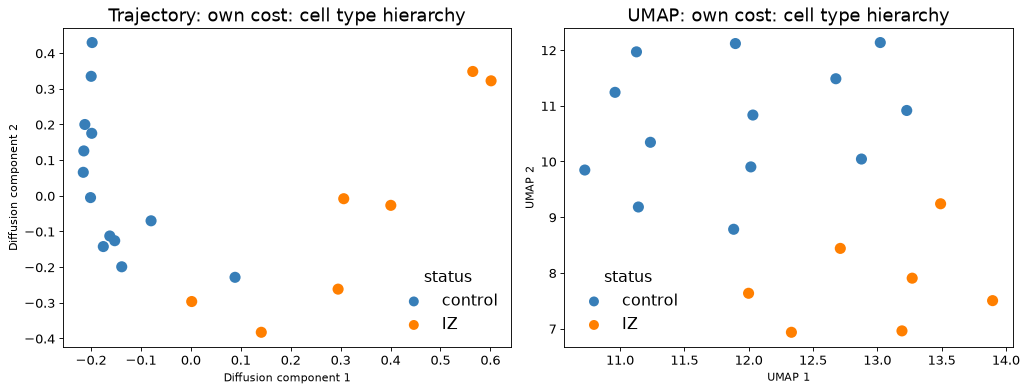

In [ ]:
major = adata.obs.groupby('cell_subtype', observed = True)['cell_type'].agg(lambda x: x.value_counts().index[0])
cost = pd.DataFrame([[0 if a == b else (0.5 if major[a] == major[b] else 1) for b in major.index]
                     for a in major.index], index = major.index, columns = major.index)
run_setting('own cost: cell type hierarchy', cost_method = 'precomputed', cost = cost)

##### Transport method (`regularized`):
<div class="alert alert-block alert-info">
- `'unreg'` (default): exact optimal transport.
- `'sinkhorn'`: entropic (Sinkhorn) optimal transport with strength `reg` (default 0.1). It is smoother, but the distance of a sample to itself is not 0.
- `'sinkhorn_divergence'`: Sinkhorn, corrected so that the distance of a sample to itself is 0.
- `'unbalanced'`: the proportions do not have to be matched exactly; mass that is not moved is penalised with strength `reg_m` (default 1). Smaller values make the distance less sensitive to rare cell types and outliers; large values give almost the same result as `'unreg'`.
</div>

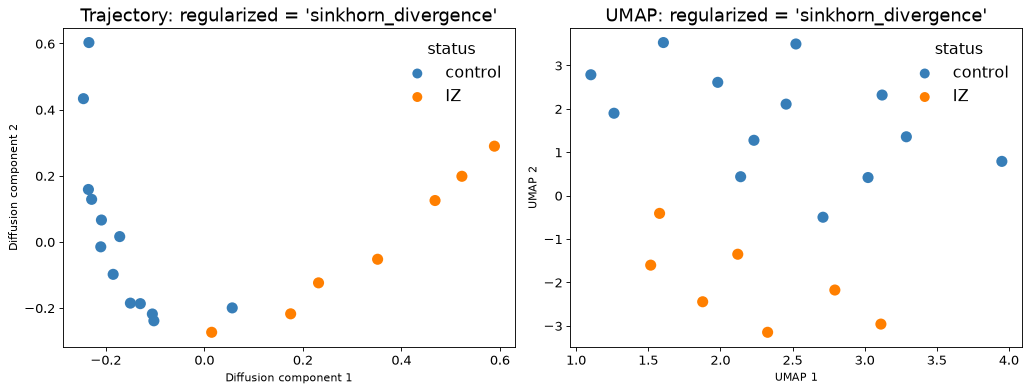

In [ ]:
run_setting("regularized = 'sinkhorn_divergence'", regularized = 'sinkhorn_divergence')

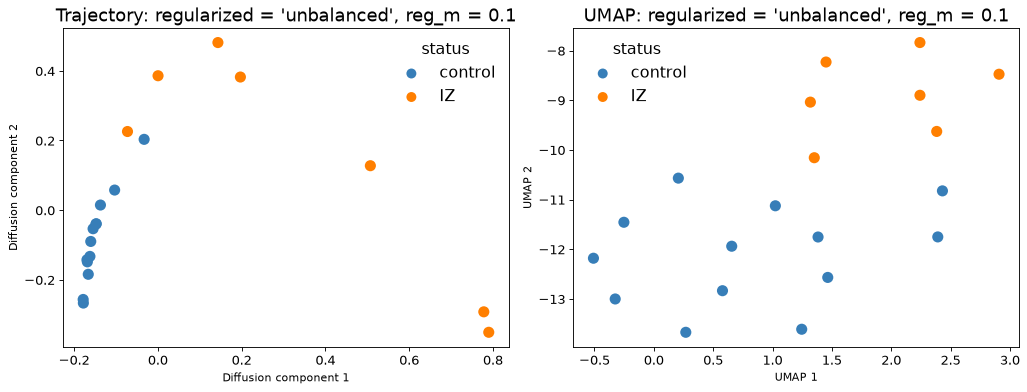

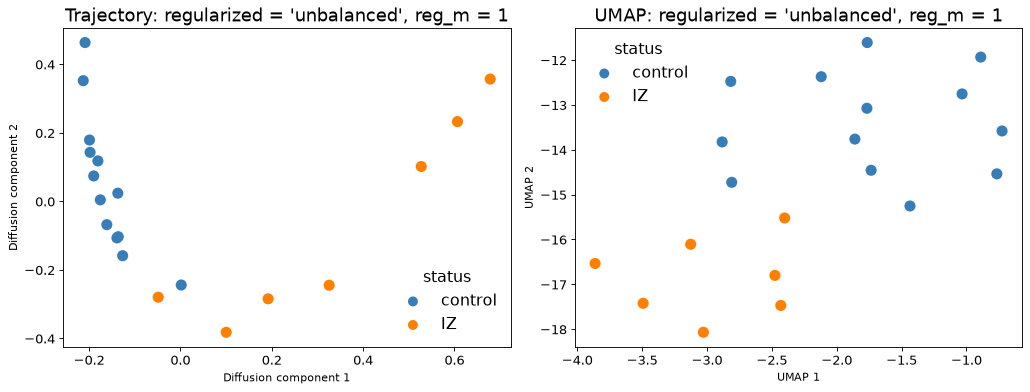

In [ ]:
for reg_m in [0.1, 1]:
    run_setting(f"regularized = 'unbalanced', reg_m = {reg_m}", regularized = 'unbalanced', reg_m = reg_m)

##### Summary:
<div class="alert alert-block alert-info">
The table shows the computation time of the Wasserstein distance and the Silhouette score of the status for every setting.
</div>

In [ ]:
summary = pd.DataFrame(results)
summary

,setting,seconds,silhouette
0,default,0.3,0.492
1,n_pcs = 2,0.2,0.572
2,n_pcs = 5,0.2,0.513
3,n_pcs = 10,0.2,0.512
4,n_pcs = 25,0.3,0.493
5,n_pcs = 30,0.3,0.492
6,centroid = 'mean',0.2,0.484
7,metric = 'correlation',0.3,0.492
8,metric = 'euclidean',0.3,0.462
9,metric = 'sqeuclidean',0.3,0.525


##### Conclusion:
<div class="alert alert-block alert-info">
For this data, all settings place the control samples at one end and the IZ samples at the other end of the trajectory. The default settings are a good choice here, and they are also among the fastest.

- Fewer principal components (`n_pcs`) or unbalanced transport separate control and IZ a bit more.
- `'distribution'`, `'graph'`, `'expression'` and `'jaccard'` take a few seconds and give a lower score here. They are useful when cell types have sub-groups, when the PCA is affected by batch effects, or to use gene expression directly.
- The computation times are for 115,517 cells, 33 cell types and 20 samples.
</div>